<a href="https://colab.research.google.com/github/psmpriya/secondrepo/blob/main/dl_cca_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import sys, platform, torch, tensorflow as tf, keras, numpy as np
print(f"PyTorch {torch.__version__} (CUDA {torch.version.cuda}), as installed in Google Colab")
print(f"TensorFlow {tf.__version__} (Keras {keras.__version__}), as installed in Google Colab")
print("Python", sys.version.split()[0], "| NumPy", np.__version__, "| OS", platform.platform())
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "None")

PyTorch 2.14.1+cpu (CUDA None), as installed in Google Colab
TensorFlow 2.21.0 (Keras 3.13.2), as installed in Google Colab
Python 3.13.18 | NumPy 2.4.6 | OS Linux-6.6.159+-x86_64-with-glibc2.39
GPU: None


In [ ]:
import os, psutil, subprocess
print("CPU:", subprocess.getoutput("lscpu | grep 'Model name'").split(":")[1].strip())
print("Cores:", os.cpu_count(), "| RAM: %.1f GB" % (psutil.virtual_memory().total / 1e9))

CPU: Intel(R) Xeon(R) CPU @ 2.20GHz
Cores: 2 | RAM: 13.6 GB


In [ ]:
import numpy as np, pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, precision_recall_fscore_support

df = pd.read_csv("http://storage.googleapis.com/download.tensorflow.org/data/ecg.csv", header=None)
X = df.iloc[:, :-1].values.astype("float32"); y = (df.iloc[:, -1].values == 0).astype(int)  # 1 = abnormal
X_tr, X_tmp, y_tr, y_tmp = train_test_split(X, y, test_size=0.4, stratify=y, random_state=42)
X_val, X_te, y_val, y_te = train_test_split(X_tmp, y_tmp, test_size=0.5, stratify=y_tmp, random_state=42)
X_trn = X_tr[y_tr == 0]                                   # normal beats only
lo, hi = X_trn.min(), X_trn.max()
sc = lambda a: np.clip((a - lo) / (hi - lo), 0, 1).astype("float32")
X_trn, X_val, X_te = sc(X_trn), sc(X_val), sc(X_te)
print(X.shape, len(X_tr), len(X_trn), len(X_val), len(X_te))

def evaluate(err_val, err_te):                            # threshold picked on validation F1
    ths = np.linspace(err_val.min(), err_val.max(), 200)
    f1s = [precision_recall_fscore_support(y_val, err_val > t, average="binary", zero_division=0)[2] for t in ths]
    t = ths[int(np.argmax(f1s))]
    p, r, f, _ = precision_recall_fscore_support(y_te, err_te > t, average="binary", zero_division=0)
    print(f"threshold={t:.5f}  ROC-AUC={roc_auc_score(y_te, err_te):.4f}  P={p:.4f}  R={r:.4f}  F1={f:.4f}")

(4998, 140) 2998 1751 1000 1000


In [ ]:
import torch, torch.nn as nn, time
torch.manual_seed(42)

class AE(nn.Module):
    def __init__(self):
        super().__init__()
        self.enc = nn.Sequential(nn.Linear(140,64), nn.ReLU(), nn.Linear(64,32), nn.ReLU(),
                                 nn.Linear(32,16), nn.ReLU())
        self.dec = nn.Sequential(nn.Linear(16,32), nn.ReLU(), nn.Linear(32,64), nn.ReLU(),
                                 nn.Linear(64,140), nn.Sigmoid())
    def forward(self, x): return self.dec(self.enc(x))

model = AE(); loss_fn = nn.MSELoss(); opt = torch.optim.Adam(model.parameters(), lr=1e-3)
loader = torch.utils.data.DataLoader(torch.from_numpy(X_trn), batch_size=64, shuffle=True)
Xvn = torch.from_numpy(X_val[y_val == 0])                 # normal validation beats

t_start = time.time()
for ep in range(50):
    model.train(); t0 = time.time(); tot = 0
    for x in loader:
        opt.zero_grad(); loss = loss_fn(model(x), x); loss.backward(); opt.step()
        tot += loss.item() * len(x)
    model.eval()
    with torch.no_grad(): vl = loss_fn(model(Xvn), Xvn).item()
    print(f"Epoch {ep+1}/50  loss={tot/len(X_trn):.5f}  val_loss={vl:.5f}  time={time.time()-t0:.2f}s")
print("Total training time: %.1f s" % (time.time() - t_start))

def errors(X):
    model.eval()
    with torch.no_grad(): x = torch.from_numpy(X); return ((model(x) - x) ** 2).mean(1).numpy()
evaluate(errors(X_val), errors(X_te))

Epoch 1/50  loss=0.00894  val_loss=0.00444  time=0.11s
Epoch 2/50  loss=0.00262  val_loss=0.00174  time=0.08s
Epoch 3/50  loss=0.00173  val_loss=0.00162  time=0.08s
Epoch 4/50  loss=0.00169  val_loss=0.00162  time=0.07s
Epoch 5/50  loss=0.00169  val_loss=0.00162  time=0.07s
Epoch 6/50  loss=0.00168  val_loss=0.00162  time=0.07s
Epoch 7/50  loss=0.00168  val_loss=0.00161  time=0.07s
Epoch 8/50  loss=0.00168  val_loss=0.00162  time=0.06s
Epoch 9/50  loss=0.00168  val_loss=0.00161  time=0.07s
Epoch 10/50  loss=0.00167  val_loss=0.00161  time=0.08s
Epoch 11/50  loss=0.00167  val_loss=0.00160  time=0.09s
Epoch 12/50  loss=0.00166  val_loss=0.00160  time=0.06s
Epoch 13/50  loss=0.00166  val_loss=0.00160  time=0.07s
Epoch 14/50  loss=0.00165  val_loss=0.00158  time=0.09s
Epoch 15/50  loss=0.00163  val_loss=0.00158  time=0.07s
Epoch 16/50  loss=0.00161  val_loss=0.00153  time=0.12s
Epoch 17/50  loss=0.00155  val_loss=0.00147  time=0.06s
Epoch 18/50  loss=0.00144  val_loss=0.00133  time=0.06s
E

In [ ]:
import tensorflow as tf, time
from tensorflow import keras
from tensorflow.keras import layers
keras.utils.set_random_seed(42)

inp = keras.Input((140,))
x = layers.Dense(64, activation="relu")(inp)
x = layers.Dense(32, activation="relu")(x)
z = layers.Dense(16, activation="relu")(x)
x = layers.Dense(32, activation="relu")(z)
x = layers.Dense(64, activation="relu")(x)
out = layers.Dense(140, activation="sigmoid")(x)
model = keras.Model(inp, out)
model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="mse")

Xvn = X_val[y_val == 0]                                   # normal validation beats
t_start = time.time()
hist = model.fit(X_trn, X_trn, epochs=50, batch_size=64, shuffle=True, validation_data=(Xvn, Xvn))
print("Total training time: %.1f s" % (time.time() - t_start))

def errors(X): return np.mean((model.predict(X, verbose=0) - X) ** 2, axis=1)
evaluate(errors(X_val), errors(X_te))

Epoch 1/50
28/28 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - loss: 0.0076 - val_loss: 0.0033
Epoch 2/50
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0023 - val_loss: 0.0017
Epoch 3/50
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0017 - val_loss: 0.0016
Epoch 4/50
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0016 - val_loss: 0.0016
Epoch 5/50
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0016 - val_loss: 0.0015
Epoch 6/50
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0015 - val_loss: 0.0014
Epoch 7/50
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0014 - val_loss: 0.0013
Epoch 8/50
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0012 - val_loss: 0.0012
Epoch 9/50
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0011 - val_loss: 0.0011
Epoch 10/50
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0010 - val_loss: 9.6972e-04
Epoch 11/50
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 9.2447e-04 - val_loss: 8.4030e-04
Epoch 12/50
28/28 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 8.

In [ ]:
import psutil, os
print("Peak-ish RAM (RSS): %.0f MB" % (psutil.Process(os.getpid()).memory_info().rss / 1e6))
t0 = time.time()
for i in range(200): errors(X_te[i:i+1])                  # batch size 1
print("Inference: %.2f ms per beat" % ((time.time() - t0) / 200 * 1000))

Peak-ish RAM (RSS): 1252 MB
Inference: 99.94 ms per beat


In [ ]:
from sklearn.metrics import accuracy_score, confusion_matrix
etr, ev, et = errors(sc(X_tr)), errors(X_val), errors(X_te)
ths = np.linspace(ev.min(), ev.max(), 200)
f1s = [precision_recall_fscore_support(y_val, ev > t_, average="binary", zero_division=0)[2] for t_ in ths]
t = ths[int(np.argmax(f1s))]
print("Threshold: %.5f" % t)
for n, e, yy in [("Train", etr, y_tr), ("Validation", ev, y_val), ("Test", et, y_te)]:
    print(f"{n} accuracy: {accuracy_score(yy, e > t):.4f}")
print("Test confusion matrix [[TN, FP],[FN, TP]]:\n", confusion_matrix(y_te, et > t))
print("Mean test error  normal: %.5f  abnormal: %.5f" % (et[y_te == 0].mean(), et[y_te == 1].mean()))

Threshold: 0.00195
Train accuracy: 0.9843
Validation accuracy: 0.9800
Test accuracy: 0.9770
Test confusion matrix [[TN, FP],[FN, TP]]:
 [[572  12]
 [ 11 405]]
Mean test error  normal: 0.00049  abnormal: 0.00368


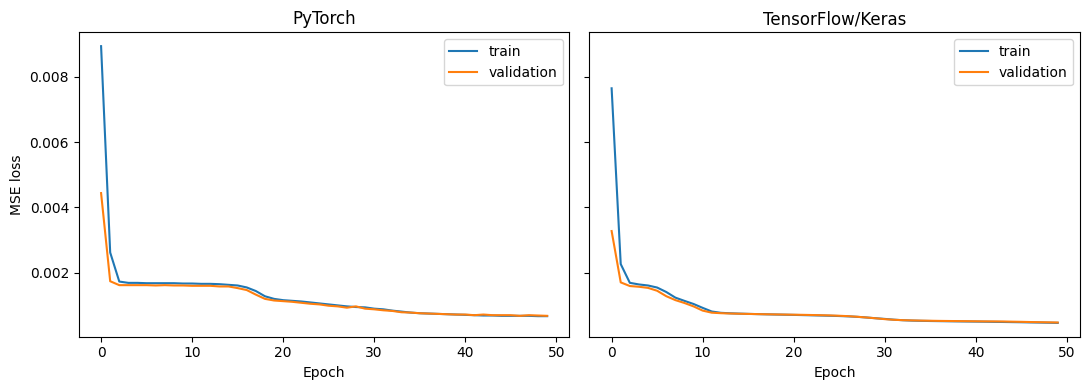

In [ ]:
import matplotlib.pyplot as plt

# PyTorch values copied from the printed training log (5 decimals)
tr_hist = [0.00894,0.00262,0.00173,0.00169,0.00169,0.00168,0.00168,0.00168,0.00168,0.00167,
           0.00167,0.00166,0.00166,0.00165,0.00163,0.00161,0.00155,0.00144,0.00128,0.00120,
           0.00116,0.00114,0.00112,0.00109,0.00106,0.00103,0.00100,0.00097,0.00095,0.00094,
           0.00090,0.00088,0.00084,0.00081,0.00078,0.00076,0.00075,0.00074,0.00073,0.00072,
           0.00071,0.00070,0.00069,0.00069,0.00068,0.00068,0.00068,0.00068,0.00067,0.00067]
va_hist = [0.00444,0.00174,0.00162,0.00162,0.00162,0.00162,0.00161,0.00162,0.00161,0.00161,
           0.00160,0.00160,0.00160,0.00158,0.00158,0.00153,0.00147,0.00133,0.00120,0.00115,
           0.00113,0.00111,0.00108,0.00105,0.00103,0.00099,0.00097,0.00093,0.00097,0.00090,
           0.00088,0.00085,0.00083,0.00079,0.00078,0.00076,0.00075,0.00074,0.00073,0.00072,
           0.00072,0.00070,0.00072,0.00070,0.00070,0.00070,0.00068,0.00070,0.00069,0.00068]

fig, ax = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
ax[0].plot(tr_hist, label="train"); ax[0].plot(va_hist, label="validation"); ax[0].set_title("PyTorch")
ax[1].plot(hist.history["loss"], label="train"); ax[1].plot(hist.history["val_loss"], label="validation"); ax[1].set_title("TensorFlow/Keras")
for a in ax: a.set_xlabel("Epoch"); a.legend()
ax[0].set_ylabel("MSE loss"); plt.tight_layout(); plt.show()

In [ ]:
import torch, torch.nn as nn, time, psutil, os
from sklearn.metrics import accuracy_score, confusion_matrix
torch.manual_seed(42)
pt = AE(); opt = torch.optim.Adam(pt.parameters(), lr=1e-3); lf = nn.MSELoss()
ld = torch.utils.data.DataLoader(torch.from_numpy(X_trn), batch_size=64, shuffle=True)
for ep in range(50):
    pt.train()
    for x in ld:
        opt.zero_grad(); lf(pt(x), x).backward(); opt.step()
def pt_err(X):
    pt.eval()
    with torch.no_grad(): x = torch.from_numpy(X); return ((pt(x) - x) ** 2).mean(1).numpy()
etr, ev, et = pt_err(sc(X_tr)), pt_err(X_val), pt_err(X_te)
ths = np.linspace(ev.min(), ev.max(), 200)
f1s = [precision_recall_fscore_support(y_val, ev > t_, average="binary", zero_division=0)[2] for t_ in ths]
t = ths[int(np.argmax(f1s))]
print("PyTorch threshold: %.5f" % t)
for n, e, yy in [("Train", etr, y_tr), ("Validation", ev, y_val), ("Test", et, y_te)]:
    print(f"{n} accuracy: {accuracy_score(yy, e > t):.4f}")
print(confusion_matrix(y_te, et > t))
print("Mean test error  normal: %.5f  abnormal: %.5f" % (et[y_te == 0].mean(), et[y_te == 1].mean()))
print("RAM: %.0f MB" % (psutil.Process(os.getpid()).memory_info().rss / 1e6))
for r in range(3):
    t0 = time.time()
    for i in range(200): pt_err(X_te[i:i+1])
    print("Inference run %d: %.2f ms per beat" % (r + 1, (time.time() - t0) / 200 * 1000))

PyTorch threshold: 0.00275
Train accuracy: 0.9750
Validation accuracy: 0.9760
Test accuracy: 0.9700
[[567  17]
 [ 13 403]]
Mean test error  normal: 0.00069  abnormal: 0.00628
RAM: 1267 MB
Inference run 1: 0.80 ms per beat
Inference run 2: 0.59 ms per beat
Inference run 3: 1.28 ms per beat
